# Adult GAN and conditional GAN

Question: after validation-only selection, how do a linear generator head and a sigmoid head compare, with and without an income condition, on the supplied Adult ARFF?

The sigmoid head is a reconstruction from a description of the architecture; its original source code was not available. It is the same hidden stack plus a final sigmoid, with min-max scaling chosen for that range.

## Protocol

- File: `data/adult.arff`, 32,561 rows, 15 attributes, income `<=50K` / `>50K`. `education` is dropped. `?` stays a category. No other Adult file is substituted.
- Seeds 42, 68, and 124. Each seed is a stratified 80/20 train/test split, then a stratified 20% selection slice inside train. The scaler and dummy columns are fit on the fit slice only.
- Linear head: no final activation, numeric columns standardized. Sigmoid head: final sigmoid, numeric columns scaled to `[0, 1]`.
- One primary configuration. `search_grid` is not trained. Adam, `betas=(0.5, 0.999)`, learning rate `1e-3`, latent 64, hidden 128, batch 64, dropout 0, weight decay 0, 120 epochs.
- Every 10 epochs the generator is scored on the full selection slice. The same real rows and the same noise seed are reused, so checkpoints differ by weights rather than by a new draw. A cGAN checkpoint is conditioned on those rows' own income labels. An unconditional generator is not given labels.
- Scores are computed after decoding into one domain: inverse-transformed numerics, plus a hard category (argmax inside each original attribute; an all-zero group stays empty). Raw standardized rows are not compared with raw min-max rows.
- Selection score: `abs(ROC-AUC - 0.5)` of a balanced random forest (80 trees, depth 16, 4-fold) on that decoded slice, and only among checkpoints that pass the validity gates (finite, not collapsed, numeric values inside a loose neighborhood of the real slice and inside plausible bounds, categorical codes not wildly outside `[-0.5, 1.5]`). Generator and discriminator losses are training diagnostics. A small loss is not a reason to keep a model, because a collapsed generator can look calm under that loss.
- If every checkpoint fails the gates, the run has no selected model and is not given a held-out success number.
- Final detection uses held-out real test rows and a fresh synthetic draw. cGAN conditions for that draw are resampled from the fit-slice labels, not from the test labels. The detector is a different protocol: 200-tree forest, four stratified 50/50 holdouts, `random_state` 124. Its AUC is not used to pick the checkpoint or the seed.
- Efficacy is cGAN only. One forest is fit on decoded real fit rows, another on decoded synthetic rows conditioned on the fit labels. Both are scored on the decoded real test set. The ratio is `synthetic_auc / real_auc`.

## Run plan from a capacity check

CPU only, 16 GB RAM, no CUDA. One epoch on the fit slice took about 1.2 s, and a small detection forest took under a second. Twelve runs of 120 epochs, with a checkpoint every 10 epochs, are on the order of an hour. That estimate is not a stopping rule.


In [1]:
%matplotlib inline

import platform
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch

ROOT = Path.cwd()
if not (ROOT / "main.py").exists():
    raise FileNotFoundError("Start Jupyter in the folder that contains main.py.")
sys.path.insert(0, str(ROOT))

from main import (
    CGAN_EPOCHS,
    DEFAULT_PATH,
    GAN_EPOCHS,
    NUMERIC_COLUMNS,
    SPLIT_SEEDS,
    ConditionalGenerator,
    Generator,
    categorical_frequency_table,
    decode_rows,
    efficacy_ratio,
    get_device,
    heldout_detection,
    load_adult,
    prepare_experiment,
    sample_cgan,
    sample_cgan_like_train,
    sample_gan,
    save_generator,
    search_grid,
    statistical_fidelity,
    train_cgan,
    train_gan,
    unconditional_efficacy,
)

print("platform", platform.platform())
print("python", platform.python_version())
print("torch", torch.__version__, "cuda", torch.cuda.is_available())
print("numpy", np.__version__, "pandas", pd.__version__, "sklearn", sklearn.__version__)
print("device", get_device())
print("epoch lists kept from the earlier screen, not used as this run:", GAN_EPOCHS, CGAN_EPOCHS)
print("search_grid is not trained. Size of one activation at 3 epochs:", len(search_grid((3,), "linear")))


platform Windows-11-10.0.26200-SP0
python 3.13.2
torch 2.14.1+cpu cuda False
numpy 2.3.0 pandas 2.3.0 sklearn 1.7.0
device cpu
epoch lists kept from the earlier screen, not used as this run: (10, 20, 30) (15, 25, 40)
search_grid is not trained. Size of one activation at 3 epochs: 192


## Table and splits


In [2]:
frame = load_adult(DEFAULT_PATH)
print("shape", frame.shape)
print("columns", list(frame.columns))
print(frame["income"].value_counts().to_dict())
if frame.shape != (32561, 15):
    raise AssertionError(frame.shape)

bundles = {}
for seed in SPLIT_SEEDS:
    for activation in ("linear", "sigmoid"):
        bundle = prepare_experiment(frame, seed=seed, output_activation=activation)
        if set(bundle["train_index"]) & set(bundle["select_index"]):
            raise AssertionError("fit/select overlap")
        if set(bundle["train_index"]) & set(bundle["test_index"]):
            raise AssertionError("fit/test overlap")
        if set(bundle["select_index"]) & set(bundle["test_index"]):
            raise AssertionError("select/test overlap")
        bundles[(seed, activation)] = bundle
        decoded_all = decode_rows(
            bundle["x_select"], bundle["feature_names"], bundle["numeric_columns"],
            bundle["categorical_groups"], bundle["scaler"],
        )
        decoded_head = decode_rows(
            bundle["x_select"][:8], bundle["feature_names"], bundle["numeric_columns"],
            bundle["categorical_groups"], bundle["scaler"],
        )
        if decoded_all["numeric"].shape[0] != bundle["x_select"].shape[0]:
            raise AssertionError("age mean must use every selection row")
        print(
            seed, activation, bundle["scaling"],
            "fit", tuple(bundle["x_train"].shape),
            "select", tuple(bundle["x_select"].shape),
            "test", tuple(bundle["x_test"].shape),
            "full_selection_age_mean", round(float(decoded_all["numeric"][:, 0].mean()), 4),
            "n_selection_rows", int(bundle["x_select"].shape[0]),
            "first_8_rows_age_mean_not_the_slice", round(float(decoded_head["numeric"][:, 0].mean()), 2),
        )


Recomputed 2026-10-14 from data/adult.arff using every selection row.
shape (32561, 15)
columns ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']
{'<=50K': 24720, '>50K': 7841}
42 linear standard fit (20838, 92) select (5210, 92) test (6513, 92) full_selection_age_mean 38.6503 n_selection_rows 5210 first_8_rows_age_mean_not_the_slice 39.0
42 sigmoid minmax fit (20838, 92) select (5210, 92) test (6513, 92) full_selection_age_mean 38.6503 n_selection_rows 5210 first_8_rows_age_mean_not_the_slice 39.0
68 linear standard fit (20838, 92) select (5210, 92) test (6513, 92) full_selection_age_mean 38.6188 n_selection_rows 5210 first_8_rows_age_mean_not_the_slice 33.0
68 sigmoid minmax fit (20838, 92) select (5210, 92) test (6513, 92) full_selection_age_mean 38.6188 n_selection_rows 5210 first_8_rows_age_mean_not_the_slice 33.0
124 linear standa

## Train and select

A finished weight file is reloaded. Losses below are not the selection score.


In [3]:
BASE = {
    "latent_dim": 64,
    "batch_size": 64,
    "lr": 1e-3,
    "hidden_dim": 128,
    "dropout": 0.0,
    "weight_decay": 0.0,
    "optimizer": "Adam",
}
EPOCHS = 120
CHECKPOINT_EVERY = 10
VARIANTS = [
    {"name": "gan_linear", "kind": "gan", "output_activation": "linear"},
    {"name": "gan_sigmoid", "kind": "gan", "output_activation": "sigmoid"},
    {"name": "cgan_linear", "kind": "cgan", "output_activation": "linear"},
    {"name": "cgan_sigmoid", "kind": "cgan", "output_activation": "sigmoid"},
]
CHECKPOINT_DIR = ROOT / "checkpoints"
CHECKPOINT_DIR.mkdir(exist_ok=True)
device = get_device()

def build_generator(kind, config, feature_dim):
    if kind == "gan":
        return Generator(
            config["latent_dim"], feature_dim, hidden_dim=config["hidden_dim"],
            dropout=config["dropout"], output_activation=config["output_activation"],
        )
    return ConditionalGenerator(
        config["latent_dim"], 2, feature_dim, hidden_dim=config["hidden_dim"],
        dropout=config["dropout"], output_activation=config["output_activation"],
    )

runs = []
for variant in VARIANTS:
    for seed in SPLIT_SEEDS:
        bundle = bundles[(seed, variant["output_activation"])]
        config = {**BASE, "epochs": EPOCHS, "output_activation": variant["output_activation"]}
        path = CHECKPOINT_DIR / f"{variant['name']}_seed{seed}.pt"
        if path.exists():
            saved = torch.load(path, map_location="cpu", weights_only=False)
            generator = build_generator(variant["kind"], saved["config"], bundle["x_train"].shape[1])
            generator.load_state_dict(saved["state_dict"])
            run = {
                "generator": generator,
                "config": saved["config"],
                "seed": seed,
                "kind": saved["kind"],
                "label_dim": saved.get("label_dim"),
                "d_loss": saved["d_loss"],
                "g_loss": saved["g_loss"],
                "checkpoints": saved["checkpoints"],
                "selected_epoch": saved["selected_epoch"],
                "acceptable": saved["acceptable"],
                "selection": saved["selection"],
            }
            print("loaded", path.name, "acceptable", run["acceptable"], flush=True)
        else:
            print("training", variant["name"], "seed", seed, flush=True)
            selection = {
                "x_select": bundle["x_select"],
                "y_select": bundle["y_select"] if variant["kind"] == "cgan" else None,
                "bundle": bundle,
                "every": CHECKPOINT_EVERY,
                "sample_seed": 42,
                "detector_seed": 42,
                "n_estimators": 80,
                "max_depth": 16,
                "n_splits": 4,
                "checkpoint_dir": str(CHECKPOINT_DIR / f"{variant['name']}_seed{seed}_epochs"),
            }
            if variant["kind"] == "gan":
                run = train_gan(
                    bundle["x_train"], config, seed=seed, device=device,
                    selection=selection, log_every=10,
                )
            else:
                run = train_cgan(
                    bundle["x_train"], bundle["y_train"], config, seed=seed, device=device,
                    selection=selection, log_every=10,
                )
            save_generator(run, path)
        run["name"] = variant["name"]
        run["split_seed"] = seed
        runs.append(run)
        chosen = None if run["selected_epoch"] is None else run["selected_epoch"] + 1
        print(variant["name"], "seed", seed, "acceptable", run["acceptable"], "selected_epoch", chosen, flush=True)


training gan_linear seed 42


  checkpoint epoch 10 gap 0.5000 auc 1.0000 valid False


gan epoch 10 d_loss 0.5736 g_loss 2.7744


  checkpoint epoch 20 gap 0.5000 auc 1.0000 valid False


gan epoch 20 d_loss 0.1406 g_loss 5.6332


  checkpoint epoch 30 gap 0.5000 auc 1.0000 valid False


... (302 outputs left out)

cgan epoch 110 d_loss 100.0000 g_loss 0.0000


  checkpoint epoch 120 gap 0.5000 auc 1.0000 valid True


cgan epoch 120 d_loss 100.0000 g_loss 0.0000


cgan_sigmoid seed 124 acceptable True selected_epoch 10


## Loss and selection curves

The black point is the accepted checkpoint. A run with no black point had no valid checkpoint.


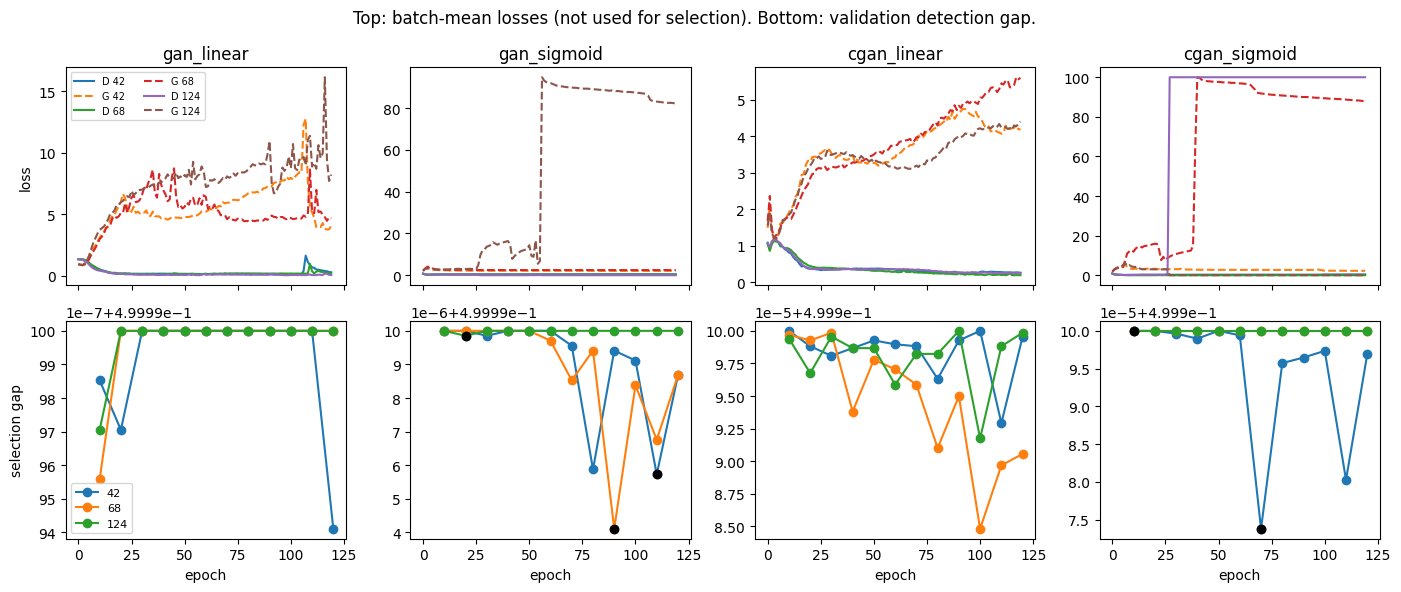

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True)
for column, variant in enumerate(VARIANTS):
    for run in runs:
        if run["name"] != variant["name"]:
            continue
        axes[0, column].plot(run["d_loss"], label=f"D {run['split_seed']}")
        axes[0, column].plot(run["g_loss"], linestyle="--", label=f"G {run['split_seed']}")
        epochs = [row["epoch_number"] for row in run["checkpoints"]]
        gaps = [row["gap"] for row in run["checkpoints"]]
        axes[1, column].plot(epochs, gaps, marker="o", label=str(run["split_seed"]))
        if run["acceptable"] and run["selected_epoch"] is not None:
            chosen = next(row for row in run["checkpoints"] if row["epoch"] == run["selected_epoch"])
            axes[1, column].scatter([chosen["epoch_number"]], [chosen["gap"]], color="black", zorder=3)
    axes[0, column].set_title(variant["name"])
    axes[0, column].set_ylabel("loss" if column == 0 else "")
    axes[1, column].set_xlabel("epoch")
    axes[1, column].set_ylabel("selection gap" if column == 0 else "")
axes[0, 0].legend(fontsize=7, ncol=2)
axes[1, 0].legend(fontsize=8)
fig.suptitle("Top: batch-mean losses (not used for selection). Bottom: validation detection gap.")
fig.tight_layout()
plt.show()


## Held-out detection and cGAN efficacy

Synthetic rows for detection are a new draw. Conditional labels for that draw come from the fit slice. Efficacy trains on fit-slice labels and scores the original test labels. A detection AUC near 0.5 is not treated as proof that the table is realistic, useful, or private.


In [5]:
def fit_conditions(y_fit, n_rows, seed):
    generator = np.random.default_rng(seed)
    index = generator.choice(len(y_fit), size=n_rows, replace=False)
    return torch.as_tensor(y_fit).long().view(-1)[index]

FINAL_ROWS = []
for run in runs:
    bundle = bundles[(run["split_seed"], run["config"]["output_activation"])]
    selection = run["selection"] or {}
    record = {
        "name": run["name"],
        "seed": run["split_seed"],
        "acceptable": bool(run["acceptable"]),
        "selected_epoch": None if run["selected_epoch"] is None else int(run["selected_epoch"]) + 1,
        "selection_auc": selection.get("mean_auc"),
        "selection_gap": selection.get("gap"),
        "diversity": selection.get("diversity"),
        "range_violation": selection.get("numeric_range_violation_fraction"),
        "plausible_violation": selection.get("plausible_violation_fraction"),
        "categorical_extreme": selection.get("categorical_extreme_fraction"),
        "selection_categorical_mae": selection.get("categorical_mae"),
        "selection_correlation_mae": selection.get("correlation_mae"),
        "final_auc": None,
        "final_auc_std": None,
        "final_diversity": None,
        "final_categorical_mae": None,
        "final_correlation_mae": None,
        "final_valid": None,
        "efficacy_real": None,
        "efficacy_synth": None,
        "efficacy_ratio": None,
    }
    if not run["acceptable"]:
        print(run["name"], run["split_seed"], "no valid checkpoint")
        FINAL_ROWS.append(record)
        run["final"] = record
        continue
    draw_seed = 9000 + int(run["split_seed"])
    latent_dim = int(run["config"]["latent_dim"])
    n_test = int(bundle["x_test"].shape[0])
    if run["kind"] == "gan":
        synthetic = sample_gan(run["generator"], n_test, latent_dim, draw_seed, device=device)
    else:
        conditions = fit_conditions(bundle["y_train"], n_test, draw_seed)
        synthetic, _labels = sample_cgan(
            run["generator"], conditions, latent_dim, run["label_dim"], draw_seed, device=device,
        )
    real_decoded = decode_rows(
        bundle["x_test"], bundle["feature_names"], bundle["numeric_columns"],
        bundle["categorical_groups"], bundle["scaler"],
    )
    synth_decoded = decode_rows(
        synthetic, bundle["feature_names"], bundle["numeric_columns"],
        bundle["categorical_groups"], bundle["scaler"],
    )
    fidelity = statistical_fidelity(real_decoded, synth_decoded, bundle["numeric_columns"])
    final = heldout_detection(
        real_decoded["common"], synth_decoded["common"],
        random_state=124, n_estimators=200, repeats=4,
    )
    record["final_auc"] = final["mean_auc"]
    record["final_auc_std"] = final["std_auc"]
    record["final_diversity"] = fidelity["diversity"]
    record["final_categorical_mae"] = fidelity["categorical_mae"]
    record["final_correlation_mae"] = fidelity["correlation_mae"]
    record["final_valid"] = fidelity["valid"]
    if run["kind"] == "gan":
        print(unconditional_efficacy()["reason"])
    else:
        fit_synth, fit_labels = sample_cgan_like_train(
            run["generator"], bundle["y_train"], latent_dim, run["label_dim"], draw_seed, device=device,
        )
        real_fit = decode_rows(
            bundle["x_train"], bundle["feature_names"], bundle["numeric_columns"],
            bundle["categorical_groups"], bundle["scaler"],
        )
        real_test = decode_rows(
            bundle["x_test"], bundle["feature_names"], bundle["numeric_columns"],
            bundle["categorical_groups"], bundle["scaler"],
        )
        synth_fit = decode_rows(
            fit_synth, bundle["feature_names"], bundle["numeric_columns"],
            bundle["categorical_groups"], bundle["scaler"],
        )
        efficacy = efficacy_ratio(
            real_fit["common"], bundle["y_train"], real_test["common"], bundle["y_test"],
            synth_fit["common"], fit_labels, random_state=42, n_estimators=200,
        )
        record["efficacy_real"] = efficacy["auc_real"]
        record["efficacy_synth"] = efficacy["auc_synth"]
        record["efficacy_ratio"] = efficacy["ratio"]
    print(
        run["name"], run["split_seed"],
        "final_auc", round(record["final_auc"], 4),
        "std", round(record["final_auc_std"], 4),
        "efficacy_ratio", record["efficacy_ratio"],
        flush=True,
    )
    FINAL_ROWS.append(record)
    run["final"] = record
    if run["split_seed"] == 42:
        run["plot_real"] = real_decoded
        run["plot_synth"] = synth_decoded

table = pd.DataFrame(FINAL_ROWS)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
print(table.to_string(index=False))
print()
accepted = table[table["acceptable"]]
if accepted.empty:
    print("No run passed the validity gates.")
else:
    summary = accepted.groupby("name")[["final_auc", "efficacy_ratio", "final_categorical_mae", "final_correlation_mae"]].agg(["mean", "std"])
    print(summary.to_string())


gan_linear 42 no valid checkpoint
gan_linear 68 no valid checkpoint
gan_linear 124 no valid checkpoint


The unconditional generator does not emit an income label. Copying training labels onto its rows is not a labeled-data protocol, so efficacy is omitted for the GAN.
gan_sigmoid 42 final_auc 1.0 std 0.0 efficacy_ratio None


The unconditional generator does not emit an income label. Copying training labels onto its rows is not a labeled-data protocol, so efficacy is omitted for the GAN.
gan_sigmoid 68 final_auc 1.0 std 0.0 efficacy_ratio None


The unconditional generator does not emit an income label. Copying training labels onto its rows is not a labeled-data protocol, so efficacy is omitted for the GAN.
gan_sigmoid 124 final_auc 1.0 std 0.0 efficacy_ratio None


cgan_linear 42 no valid checkpoint
cgan_linear 68 no valid checkpoint
cgan_linear 124 no valid checkpoint


cgan_sigmoid 42 final_auc 1.0 std 0.0 efficacy_ratio 0.846179103283108


cgan_sigmoid 68 no valid checkpoint


cgan_sigmoid 124 final_auc 1.0 std 0.0 efficacy_ratio 0.8338013284157528


        name  seed  acceptable  selected_epoch  selection_auc  selection_gap  diversity  range_violation  plausible_violation  categorical_extreme  selection_categorical_mae  selection_correlation_mae  final_auc  final_auc_std  final_diversity  final_categorical_mae  final_correlation_mae final_valid  efficacy_real  efficacy_synth  efficacy_ratio
  gan_linear    42       False             NaN            NaN            NaN        NaN              NaN                  NaN                  NaN                        NaN                        NaN        NaN            NaN              NaN                    NaN                    NaN        None            NaN             NaN             NaN
  gan_linear    68       False             NaN            NaN            NaN        NaN              NaN                  NaN                  NaN                        NaN                        NaN        NaN            NaN              NaN                    NaN                    NaN        None 

## Decoded marginals for split seed 42

Numeric histograms use the inverse scaler. Category bars are hard-decoded frequencies. Runs without an accepted checkpoint are omitted.


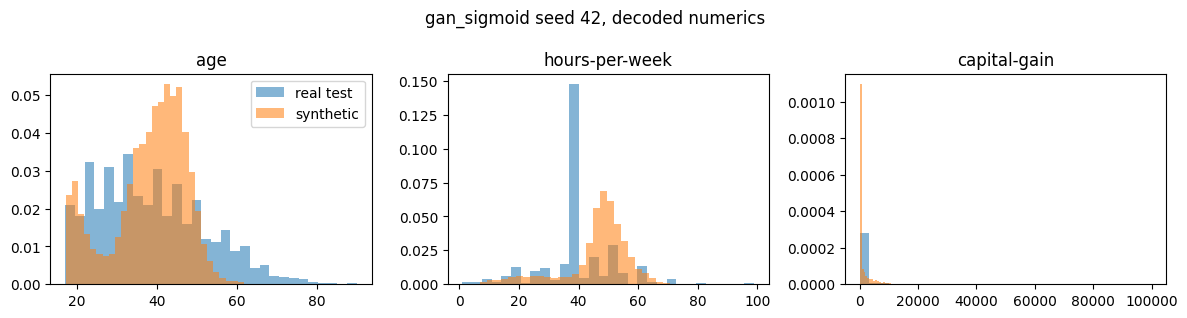

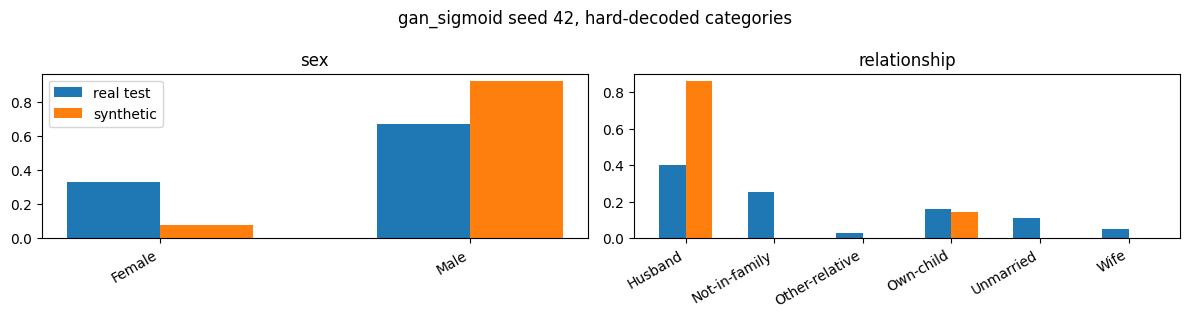

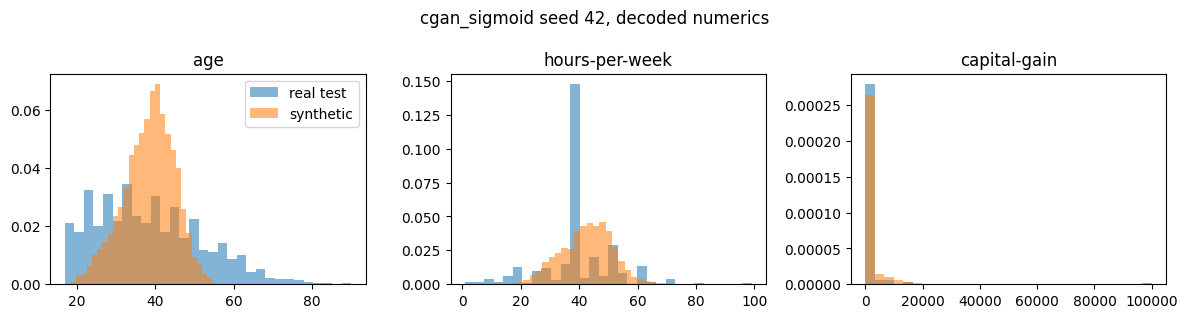

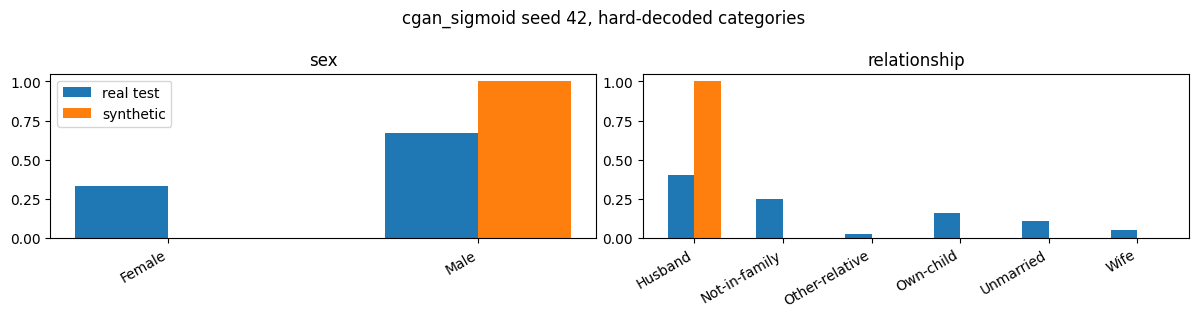

In [6]:
plot_runs = [run for run in runs if run["split_seed"] == 42 and run.get("plot_real") is not None]
if not plot_runs:
    print("Seed 42 produced no accepted checkpoint to plot.")
for run in plot_runs:
    bundle = bundles[(42, run["config"]["output_activation"])]
    real = run["plot_real"]["numeric"]
    synth = run["plot_synth"]["numeric"]
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
    for axis, column in zip(axes, ("age", "hours-per-week", "capital-gain")):
        index = NUMERIC_COLUMNS.index(column)
        axis.hist(real[:, index], bins=30, density=True, alpha=0.55, label="real test")
        axis.hist(synth[:, index], bins=30, density=True, alpha=0.55, label="synthetic")
        axis.set_title(column)
    axes[0].legend()
    fig.suptitle(run["name"] + " seed 42, decoded numerics")
    fig.tight_layout()
    plt.show()
    real_freq = categorical_frequency_table(run["plot_real"]["hard"], bundle["categorical_groups"])
    synth_freq = categorical_frequency_table(run["plot_synth"]["hard"], bundle["categorical_groups"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
    for axis, field in zip(axes, ("sex", "relationship")):
        labels = list(real_freq[field])
        x = np.arange(len(labels))
        axis.bar(x - 0.15, [real_freq[field][label] for label in labels], width=0.3, label="real test")
        axis.bar(x + 0.15, [synth_freq[field][label] for label in labels], width=0.3, label="synthetic")
        axis.set_xticks(x, labels, rotation=30, ha="right")
        axis.set_title(field)
    axes[0].legend()
    fig.suptitle(run["name"] + " seed 42, hard-decoded categories")
    fig.tight_layout()
    plt.show()


## Invalid checkpoints, and one learning-rate adjustment

The primary learning rate is `1e-3`. Every linear checkpoint failed the plausible-numeric gate, and `cgan_sigmoid` seed 68 never produced a valid checkpoint. This section reads those saved checkpoints and states which gate failed. It does not turn a failed checkpoint into a selected model.

The adjustment is one change: Adam learning rate `1e-4`, same width, batch, and 120 epochs, only for `gan_linear` and `cgan_linear` at split seed 42 and for the collapsed `cgan_sigmoid` seed 68. It asks whether the smaller step brings linear outputs inside the numeric bounds or stops that conditional collapse. It is not a second search.


In [1]:
from pathlib import Path
import torch

from main import (
    NUMERIC_COLUMNS,
    PLAUSIBLE_NUMERIC,
    ConditionalGenerator,
    Generator,
    decode_rows,
    load_adult,
    prepare_experiment,
    sample_gan,
    sample_cgan,
)

ROOT = Path.cwd()
CHECKPOINT_DIR = ROOT / "checkpoints"
frame = load_adult()
device = torch.device("cpu")

def load_epoch_generator(name, kind, activation, feature_dim, epoch_number):
    config_path = CHECKPOINT_DIR / f"{name}.pt"
    saved = torch.load(config_path, map_location="cpu", weights_only=False)
    if kind == "gan":
        generator = Generator(64, feature_dim, hidden_dim=128, dropout=0.0, output_activation=activation)
    else:
        generator = ConditionalGenerator(64, 2, feature_dim, hidden_dim=128, dropout=0.0, output_activation=activation)
    state = torch.load(
        CHECKPOINT_DIR / f"{name}_epochs" / f"epoch_{epoch_number:04d}.pt",
        map_location="cpu", weights_only=False,
    )
    generator.load_state_dict(state)
    generator.eval()
    return generator, saved

def column_report(decoded):
    lines = []
    for index, column in enumerate(NUMERIC_COLUMNS):
        values = decoded["numeric"][:, index]
        low, high = PLAUSIBLE_NUMERIC[column]
        fraction = float(((values < low) | (values > high)).mean())
        lines.append(
            f"  {column}: outside {fraction:.3f} min {values.min():.2f} mean {values.mean():.2f} max {values.max():.2f}"
        )
    return "\n".join(lines)

failed = [
    ("gan_linear", 42, "gan", "linear"),
    ("cgan_linear", 42, "cgan", "linear"),
    ("cgan_sigmoid", 68, "cgan", "sigmoid"),
]
for name, seed, kind, activation in failed:
    bundle = prepare_experiment(frame, seed=seed, output_activation=activation)
    saved = torch.load(CHECKPOINT_DIR / f"{name}_seed{seed}.pt", map_location="cpu", weights_only=False)
    rows = saved["checkpoints"]
    least_implausible = min(rows, key=lambda row: (row["plausible_violation_fraction"], row["numeric_mean_shift"]))
    print(
        name, "seed", seed,
        "checkpoints", len(rows),
        "least plausible-violation", least_implausible["plausible_violation_fraction"],
        "at epoch", least_implausible["epoch_number"],
        "auc", least_implausible["mean_auc"],
        "diversity", least_implausible["diversity"],
        "mean shift", least_implausible["numeric_mean_shift"],
        "categorical extreme", least_implausible["categorical_extreme_fraction"],
    )
    generator, _saved = load_epoch_generator(
        f"{name}_seed{seed}", kind, activation, bundle["x_train"].shape[1],
        least_implausible["epoch_number"],
    )
    if kind == "gan":
        synthetic = sample_gan(generator, bundle["x_select"].shape[0], 64, 42, device=device)
    else:
        synthetic, _labels = sample_cgan(
            generator, bundle["y_select"], 64, 2, 42, device=device,
        )
    decoded = decode_rows(
        synthetic, bundle["feature_names"], bundle["numeric_columns"],
        bundle["categorical_groups"], bundle["scaler"],
    )
    print(column_report(decoded))


gan_linear seed 42 checkpoints 12 least plausible-violation 0.09648112603966731 at epoch 60 auc 1.0 diversity 1.0 mean shift 0.2760669186739764 categorical extreme 0.0
  age: outside 0.000 min 6.27 mean 36.81 max 107.75
  fnlwgt: outside 0.015 min -178205.37 mean 180409.94 max 681097.70
  education-num: outside 0.000 min -0.92 mean 11.51 max 19.80
  capital-gain: outside 0.155 min -266.61 mean 1457.58 max 41742.58
  capital-loss: outside 0.408 min -15.04 mean 2.77 max 27.78
  hours-per-week: outside 0.000 min -4.70 mean 47.94 max 102.08


cgan_linear seed 42 checkpoints 12 least plausible-violation 0.039315419065898916 at epoch 10 auc 1.0 diversity 1.0 mean shift 0.08271503578722107 categorical extreme 0.004015087265098425
  age: outside 0.000 min 4.70 mean 37.45 max 106.13
  fnlwgt: outside 0.022 min -96131.76 mean 184748.11 max 831146.74
  education-num: outside 0.000 min -0.33 mean 10.24 max 17.63
  capital-gain: outside 0.103 min -2002.65 mean 1400.70 max 32743.08
  capital-loss: outside 0.106 min -119.79 mean 41.19 max 234.76
  hours-per-week: outside 0.005 min -35.98 mean 42.02 max 109.65


cgan_sigmoid seed 68 checkpoints 12 least plausible-violation 0.0 at epoch 10 auc 1.0 diversity 0.7312859884836852 mean shift 2.144632193381882 categorical extreme 0.0
  age: outside 0.000 min 89.80 mean 89.99 max 90.00
  fnlwgt: outside 0.000 min 14878.00 mean 14930.49 max 16287.81
  education-num: outside 0.000 min 15.99 mean 16.00 max 16.00
  capital-gain: outside 0.000 min 0.00 mean 0.09 max 5.88
  capital-loss: outside 0.000 min 0.00 mean 0.05 max 1.41
  hours-per-week: outside 0.000 min 98.84 mean 98.99 max 99.00


In [2]:
import numpy as np
import torch

from main import (
    heldout_detection,
    sample_cgan,
    sample_cgan_like_train,
    sample_gan,
    save_generator,
    train_cgan,
    train_gan,
    decode_rows,
    statistical_fidelity,
    efficacy_ratio,
)

ADJUSTED = [
    {"name": "gan_linear", "kind": "gan", "output_activation": "linear", "seed": 42},
    {"name": "cgan_linear", "kind": "cgan", "output_activation": "linear", "seed": 42},
    {"name": "cgan_sigmoid", "kind": "cgan", "output_activation": "sigmoid", "seed": 68},
]
LR = 1e-4

for spec in ADJUSTED:
    bundle = prepare_experiment(frame, seed=spec["seed"], output_activation=spec["output_activation"])
    config = {
        "latent_dim": 64, "batch_size": 64, "lr": LR, "hidden_dim": 128,
        "dropout": 0.0, "weight_decay": 0.0, "optimizer": "Adam",
        "epochs": 120, "output_activation": spec["output_activation"],
    }
    path = CHECKPOINT_DIR / f"{spec['name']}_seed{spec['seed']}_lr1e-4.pt"
    selection = {
        "x_select": bundle["x_select"],
        "y_select": bundle["y_select"] if spec["kind"] == "cgan" else None,
        "bundle": bundle,
        "every": 10,
        "sample_seed": 42,
        "detector_seed": 42,
        "n_estimators": 80,
        "max_depth": 16,
        "n_splits": 4,
        "checkpoint_dir": str(CHECKPOINT_DIR / f"{spec['name']}_seed{spec['seed']}_lr1e-4_epochs"),
    }
    if path.exists():
        saved = torch.load(path, map_location="cpu", weights_only=False)
        print("loaded", path.name, "acceptable", saved["acceptable"], flush=True)
        run = saved
        generator = load_epoch_generator(
            f"{spec['name']}_seed{spec['seed']}_lr1e-4", spec["kind"], spec["output_activation"],
            bundle["x_train"].shape[1],
            120 if saved["selected_epoch"] is None else saved["selected_epoch"] + 1,
        )[0]
        if saved["acceptable"]:
            generator.load_state_dict(saved["state_dict"])
        run = {
            "generator": generator,
            "acceptable": saved["acceptable"],
            "selected_epoch": saved["selected_epoch"],
            "selection": saved["selection"],
            "checkpoints": saved["checkpoints"],
            "kind": spec["kind"],
            "label_dim": saved.get("label_dim"),
            "config": saved["config"],
        }
    else:
        print("training", spec["name"], "seed", spec["seed"], "lr", LR, flush=True)
        if spec["kind"] == "gan":
            run = train_gan(bundle["x_train"], config, seed=spec["seed"], device=device, selection=selection, log_every=20)
        else:
            run = train_cgan(
                bundle["x_train"], bundle["y_train"], config, seed=spec["seed"],
                device=device, selection=selection, log_every=20,
            )
        save_generator(run, path)
    print(
        spec["name"], "lr", LR, "acceptable", run["acceptable"],
        "selected_epoch", None if run["selected_epoch"] is None else run["selected_epoch"] + 1,
        flush=True,
    )
    if run["checkpoints"]:
        least = min(run["checkpoints"], key=lambda row: row["plausible_violation_fraction"])
        print(
            "  least plausible violation", least["plausible_violation_fraction"],
            "epoch", least["epoch_number"],
            "auc", least["mean_auc"],
            "diversity", least["diversity"],
            "mean shift", least["numeric_mean_shift"],
        )
    if not run["acceptable"]:
        continue
    draw_seed = 9000 + int(spec["seed"])
    n_test = int(bundle["x_test"].shape[0])
    if spec["kind"] == "gan":
        synthetic = sample_gan(run["generator"], n_test, 64, draw_seed, device=device)
    else:
        chosen = np.random.default_rng(draw_seed).choice(len(bundle["y_train"]), size=n_test, replace=False)
        synthetic, _labels = sample_cgan(
            run["generator"], bundle["y_train"][chosen], 64, run["label_dim"], draw_seed, device=device,
        )
    real_decoded = decode_rows(
        bundle["x_test"], bundle["feature_names"], bundle["numeric_columns"],
        bundle["categorical_groups"], bundle["scaler"],
    )
    synth_decoded = decode_rows(
        synthetic, bundle["feature_names"], bundle["numeric_columns"],
        bundle["categorical_groups"], bundle["scaler"],
    )
    fidelity = statistical_fidelity(real_decoded, synth_decoded, bundle["numeric_columns"])
    final = heldout_detection(real_decoded["common"], synth_decoded["common"], random_state=124, n_estimators=200, repeats=4)
    print(
        "  final_auc", round(final["mean_auc"], 4),
        "std", round(final["std_auc"], 6),
        "final_valid", fidelity["valid"],
        "plausible", round(fidelity["plausible_violation_fraction"], 4),
        flush=True,
    )
    if spec["kind"] == "cgan":
        fit_synth, fit_labels = sample_cgan_like_train(
            run["generator"], bundle["y_train"], 64, run["label_dim"], draw_seed, device=device,
        )
        real_fit = decode_rows(bundle["x_train"], bundle["feature_names"], bundle["numeric_columns"], bundle["categorical_groups"], bundle["scaler"])
        real_test = decode_rows(bundle["x_test"], bundle["feature_names"], bundle["numeric_columns"], bundle["categorical_groups"], bundle["scaler"])
        synth_fit = decode_rows(fit_synth, bundle["feature_names"], bundle["numeric_columns"], bundle["categorical_groups"], bundle["scaler"])
        efficacy = efficacy_ratio(real_fit["common"], bundle["y_train"], real_test["common"], bundle["y_test"], synth_fit["common"], fit_labels, n_estimators=200)
        print("  efficacy_ratio", efficacy["ratio"], "real", efficacy["auc_real"], "synth", efficacy["auc_synth"])


training gan_linear seed 42 lr 0.0001


  checkpoint epoch 10 gap 0.5000 auc 1.0000 valid False


  checkpoint epoch 20 gap 0.5000 auc 1.0000 valid False


gan epoch 20 d_loss 1.3098 g_loss 0.7556


  checkpoint epoch 30 gap 0.5000 auc 1.0000 valid False


  checkpoint epoch 40 gap 0.5000 auc 1.0000 valid False


... (55 outputs left out)

cgan_sigmoid lr 0.0001 acceptable True selected_epoch 10


  least plausible violation 0.0 epoch 10 auc 1.0 diversity 1.0 mean shift 2.9068525694143865


  final_auc 1.0 std 0.0 final_valid True plausible 0.0


  efficacy_ratio 0.5968721711347247 real 0.9080366815583666 synth 0.5419818255917129


## Conditional linear model at learning rate 1e-4, remaining seeds

Seed 42 of `cgan_linear` produced one valid checkpoint at learning rate `1e-4`. The same configuration is trained on split seeds 68 and 124. `gan_linear` at this learning rate stayed invalid, so those other seeds are not repeated.


In [1]:
from pathlib import Path
import numpy as np
import torch

from main import (
    decode_rows,
    efficacy_ratio,
    heldout_detection,
    load_adult,
    prepare_experiment,
    sample_cgan,
    sample_cgan_like_train,
    save_generator,
    statistical_fidelity,
    train_cgan,
)

ROOT = Path.cwd()
CHECKPOINT_DIR = ROOT / "checkpoints"
frame = load_adult()
device = torch.device("cpu")
LR = 1e-4

print("primary runs with no accepted checkpoint")
for path in sorted(CHECKPOINT_DIR.glob("*_seed*.pt")):
    if "lr1e-4" in path.name:
        continue
    saved = torch.load(path, map_location="cpu", weights_only=False)
    if saved.get("acceptable"):
        continue
    rows = saved["checkpoints"]
    least = min(rows, key=lambda row: (row["plausible_violation_fraction"], row["numeric_mean_shift"]))
    print(
        path.stem,
        "checkpoints", len(rows),
        "least_plausible", round(least["plausible_violation_fraction"], 4),
        "epoch", least["epoch_number"],
        "auc", least["mean_auc"],
        "diversity", round(least["diversity"], 4),
        "mean_shift", round(least["numeric_mean_shift"], 4),
        "categorical_extreme", round(least["categorical_extreme_fraction"], 4),
    )

for seed in (68, 124):
    bundle = prepare_experiment(frame, seed=seed, output_activation="linear")
    config = {
        "latent_dim": 64, "batch_size": 64, "lr": LR, "hidden_dim": 128,
        "dropout": 0.0, "weight_decay": 0.0, "optimizer": "Adam",
        "epochs": 120, "output_activation": "linear",
    }
    path = CHECKPOINT_DIR / f"cgan_linear_seed{seed}_lr1e-4.pt"
    selection = {
        "x_select": bundle["x_select"],
        "y_select": bundle["y_select"],
        "bundle": bundle,
        "every": 10,
        "sample_seed": 42,
        "detector_seed": 42,
        "n_estimators": 80,
        "max_depth": 16,
        "n_splits": 4,
        "checkpoint_dir": str(CHECKPOINT_DIR / f"cgan_linear_seed{seed}_lr1e-4_epochs"),
    }
    if path.exists():
        saved = torch.load(path, map_location="cpu", weights_only=False)
        run = saved
        print("loaded", path.name, "acceptable", saved["acceptable"], flush=True)
    else:
        print("training cgan_linear seed", seed, "lr", LR, flush=True)
        run = train_cgan(
            bundle["x_train"], bundle["y_train"], config, seed=seed,
            device=device, selection=selection, log_every=20,
        )
        save_generator(run, path)
    print(
        "cgan_linear", seed, "acceptable", run["acceptable"],
        "selected_epoch", None if run["selected_epoch"] is None else run["selected_epoch"] + 1,
        flush=True,
    )
    if not run["acceptable"]:
        least = min(run["checkpoints"], key=lambda row: row["plausible_violation_fraction"])
        print(
            "  least plausible", least["plausible_violation_fraction"],
            "epoch", least["epoch_number"], "auc", least["mean_auc"],
        )
        continue
    from main import ConditionalGenerator
    generator = ConditionalGenerator(64, 2, bundle["x_train"].shape[1], hidden_dim=128, dropout=0.0, output_activation="linear")
    if "generator" in run:
        generator.load_state_dict(run["generator"].state_dict())
    else:
        generator.load_state_dict(run["state_dict"])
    generator.eval()
    draw_seed = 9000 + int(seed)
    n_test = int(bundle["x_test"].shape[0])
    chosen = np.random.default_rng(draw_seed).choice(len(bundle["y_train"]), size=n_test, replace=False)
    synthetic, _labels = sample_cgan(generator, bundle["y_train"][chosen], 64, 2, draw_seed, device=device)
    real_decoded = decode_rows(bundle["x_test"], bundle["feature_names"], bundle["numeric_columns"], bundle["categorical_groups"], bundle["scaler"])
    synth_decoded = decode_rows(synthetic, bundle["feature_names"], bundle["numeric_columns"], bundle["categorical_groups"], bundle["scaler"])
    fidelity = statistical_fidelity(real_decoded, synth_decoded, bundle["numeric_columns"])
    final = heldout_detection(real_decoded["common"], synth_decoded["common"], random_state=124, n_estimators=200, repeats=4)
    fit_synth, fit_labels = sample_cgan_like_train(generator, bundle["y_train"], 64, 2, draw_seed, device=device)
    real_fit = decode_rows(bundle["x_train"], bundle["feature_names"], bundle["numeric_columns"], bundle["categorical_groups"], bundle["scaler"])
    real_test = decode_rows(bundle["x_test"], bundle["feature_names"], bundle["numeric_columns"], bundle["categorical_groups"], bundle["scaler"])
    synth_fit = decode_rows(fit_synth, bundle["feature_names"], bundle["numeric_columns"], bundle["categorical_groups"], bundle["scaler"])
    efficacy = efficacy_ratio(real_fit["common"], bundle["y_train"], real_test["common"], bundle["y_test"], synth_fit["common"], fit_labels, n_estimators=200)
    print(
        "  final_auc", final["mean_auc"], "std", final["std_auc"],
        "final_valid", fidelity["valid"],
        "plausible", fidelity["plausible_violation_fraction"],
        "efficacy_ratio", efficacy["ratio"],
        "real", efficacy["auc_real"],
        "synth", efficacy["auc_synth"],
        flush=True,
    )


primary runs with no accepted checkpoint
cgan_linear_seed124 checkpoints 12 least_plausible 0.1005 epoch 120 auc 0.9999998526383048 diversity 1.0 mean_shift 0.1831 categorical_extreme 0.0001
cgan_linear_seed42 checkpoints 12 least_plausible 0.0393 epoch 10 auc 1.0 diversity 1.0 mean_shift 0.0827 categorical_extreme 0.004
cgan_linear_seed68 checkpoints 12 least_plausible 0.1128 epoch 80 auc 0.9999910109365957 diversity 1.0 mean_shift 0.1958 categorical_extreme 0.0
cgan_sigmoid_seed68 checkpoints 12 least_plausible 0.0 epoch 10 auc 1.0 diversity 0.7313 mean_shift 2.1446 categorical_extreme 0.0
gan_linear_seed124 checkpoints 12 least_plausible 0.0748 epoch 70 auc 1.0 diversity 1.0 mean_shift 0.175 categorical_extreme 0.0028
gan_linear_seed42 checkpoints 12 least_plausible 0.0965 epoch 60 auc 1.0 diversity 1.0 mean_shift 0.2761 categorical_extreme 0.0
gan_linear_seed68 checkpoints 12 least_plausible 0.06 epoch 110 auc 1.0 diversity 1.0 mean_shift 0.2234 categorical_extreme 0.0174


training cgan_linear seed 68 lr 0.0001


  checkpoint epoch 10 gap 0.5000 auc 1.0000 valid False


  checkpoint epoch 20 gap 0.5000 auc 1.0000 valid False


cgan epoch 20 d_loss 1.2167 g_loss 0.9230


  checkpoint epoch 30 gap 0.5000 auc 1.0000 valid False


... (32 outputs left out)

  checkpoint epoch 120 gap 0.5000 auc 1.0000 valid False


cgan epoch 120 d_loss 0.5513 g_loss 1.9766


cgan_linear 124 acceptable True selected_epoch 20


  final_auc 1.0 std 0.0 final_valid True plausible 0.01399764573417268 efficacy_ratio 0.9292897788578165 real 0.9099201548668001 synth 0.8455794994944388


## Conclusion

At learning rate `1e-3`, every linear checkpoint failed the plausible-numeric gate. The failures are negative capital-gain and capital-loss values, plus a smaller share of impossible `fnlwgt`. Categorical extremes are near zero, and the detection AUC on those checkpoints is already about 1. There is no selected linear model at this learning rate.

The sigmoid runs that passed are still separable from real rows. Held-out detection AUC is 0.999995, 0.999987, and 1.0 for `gan_sigmoid` seeds 42, 68, and 124 (mean 0.999994, sample std 0.000007). For `cgan_sigmoid` it is 0.999997 and 1.0 on seeds 42 and 124 (mean 0.999998, sample std 0.000002). Selection gaps sit at about 0.5. The kept epoch is the eligible checkpoint with the smallest full-precision abs(selection ROC-AUC - 0.5), not the first eligible checkpoint. Accepted primary epochs are 110, 90, and 20 for `gan_sigmoid` seeds 42, 68, and 124, and 70 and 10 for `cgan_sigmoid` seeds 42 and 124. The first eligible epoch on each of those runs is 10. Four selected epochs are later than that because the gap was smaller by about 1e-6 to 3e-5. `cgan_sigmoid` seed 124 stays at epoch 10 because every later eligible gap is exactly 0.5. Those differences do not rank checkpoints in any practical sense.

`cgan_sigmoid` seed 68 collapsed: epoch 10 already has plausible violation 0, diversity 0.7313, and numeric mean shift 2.14, with age near 90, education-num 16, and hours near 99. It is not an accepted model.

Conditional efficacy on the accepted `1e-3` sigmoid runs is 0.846179 (seed 42: real 0.910487, synthetic 0.770435) and 0.833801 (seed 124: real 0.909893, synthetic 0.758670). Mean ratio 0.83999, sample std 0.008752. Synthetic income labels support a weaker forest than the real fit rows. The unconditional generator has no income label, so it has no efficacy number.

Lowering the learning rate to `1e-4` does not change the detection result. `gan_linear` seed 42 stays invalid (least plausible violation 0.1155). `cgan_linear` is accepted on seeds 42 and 124 (epochs 10 and 20, plausible violations 0.0169 and 0.0140, efficacy ratios 0.844296 and 0.929290) and rejected on seed 68 (least plausible violation 0.0935). Held-out detection AUC on the accepted draws is 1.0. The same learning rate makes `cgan_sigmoid` seed 68 eligible at epoch 10, with detection AUC 1.0 and efficacy ratio 0.596872 (real 0.908037, synthetic 0.541982). The selected epoch still has numeric mean shift 2.91.

Decoded categorical MAE on the accepted primary sigmoid models is about 0.05 to 0.07. Correlation MAE is about 0.14 to 0.26. Those gaps, together with detection AUC at 1, are the result of this training setup.
